# 08 — Computed findings and capstone figures

**Objective.** Assemble the actual results, their practical implications, and unresolved validity risks.

**Cohort and interpretation.** Uses the outputs of notebooks 01–07 without additional fitting or test-set selection. Tables and PNG/PDF figures are saved under reports/injury_type_analysis. The original database and canonical injury files remain unchanged.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/injury_analysis.yaml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.injury_analysis.common import CFG, CACHE, OUT, read_table, table, conclusion, style
from src.injury_analysis.cohort import load
from src.injury_analysis import plots
style()
pd.set_option('display.max_columns', 14)


In [2]:
from src.injury_analysis.report import write_summary
a, events, spec = load()
summary = write_summary(a, events, spec)
display(Markdown(summary))

# Exploratory injury-type analysis — computed results

The existing source database was opened read-only. This is an exploratory comparison of documented MLB IL episodes, not a clinical prediction system or a final tuned model.

## Cohort and source coverage

- 5,381 canonical episodes; 3,552 pass the prespecified initial-anatomy/timing rules.
- 233,433 regular-season appearances by official pitcher/two-way IDs; 221,223 pass appearance/history/active-episode rules.
- Statcast features end 2026-09-08; injury observations end 2026-09-18. 2026 is descriptive only.
- 1,225 event/control pairs, matched on year, month, current role, five-year age band and prior-appearance experience band. Each control pitcher is used at most once. Unmatched cases remain available for outcome descriptions.
- 62 prespecified v1/context predictors survive training-period availability checks. Arm angle is descriptive in its observed era; within-game velocity decline is too sparse in this mixed-role population for the shared model.

## What the results show

Matched 1–14-day velocity differences (injury minus control, pitcher-relative z-score; exploratory pitcher bootstrap):

| analysis_group   |   mean |    low |   high |   n |
|:-----------------|-------:|-------:|-------:|----:|
| Elbow / UCL      | -0.378 | -0.554 | -0.207 | 225 |
| Forearm          | -0.299 | -0.542 | -0.033 |  84 |
| Hand / wrist     | -0.289 | -0.566 | -0.032 |  68 |
| Lower body       | -0.157 | -0.314 |  0.002 | 280 |
| Other arm        | -0.082 | -0.357 |  0.199 |  85 |
| Shoulder         | -0.389 | -0.546 | -0.241 | 276 |
| Trunk / neck     | -0.169 | -0.354 |  0.003 | 206 |

30-day chronological test results (training through 2021, validation 2022–2023, test 2024–2025; 60-day boundary embargo):

| category     |   events | prevalence   | average_precision   |   pr_lift |   lift_low |   lift_high |
|:-------------|---------:|:-------------|:--------------------|----------:|-----------:|------------:|
| Elbow / UCL  |      110 | 2.56%        | 4.32%               |      1.69 |       1.29 |        2.37 |
| Shoulder     |      125 | 3.05%        | 5.65%               |      1.85 |       1.44 |        2.49 |
| Forearm      |       38 | 1.02%        | 2.15%               |      2.10 |       1.25 |        3.59 |
| Other arm    |       38 | 0.95%        | 1.01%               |      1.06 |       0.84 |        1.56 |
| Trunk / neck |       65 | 1.65%        | 2.76%               |      1.68 |       1.19 |        2.77 |
| Lower body   |      104 | 2.30%        | 4.75%               |      2.06 |       1.51 |        3.09 |
| Hand / wrist |       29 | 0.63%        | 0.91%               |      1.44 |       1.12 |        2.38 |

PR lift ranges from 1.06 to 2.10. Lower-body lift is 2.06, so these results do not establish that the warning signals are specific to arm injuries. Category prevalences and event counts differ; overlapping uncertainty intervals do not support a reliable ranking of biological predictability.

At a retrospective 5% alert budget, requiring a warning 7–30 days before injury:

| category     |   qualifying_events |   observable_events |   alerted_events |   injury_event_recall |   observable_event_recall |   median_warning_lead_days |   false_alerts_per_pitcher_season |
|:-------------|--------------------:|--------------------:|-----------------:|----------------------:|--------------------------:|---------------------------:|----------------------------------:|
| Elbow / UCL  |                 145 |                 104 |               25 |                 0.172 |                     0.240 |                     17.000 |                             1.093 |
| Shoulder     |                 161 |                 117 |               29 |                 0.180 |                     0.248 |                     18.000 |                             1.075 |
| Forearm      |                  46 |                  36 |                8 |                 0.174 |                     0.222 |                     26.500 |                             1.116 |
| Other arm    |                  45 |                  35 |                4 |                 0.089 |                     0.114 |                     27.500 |                             1.139 |
| Trunk / neck |                  85 |                  60 |               16 |                 0.188 |                     0.267 |                     22.000 |                             1.105 |
| Lower body   |                 125 |                  93 |               28 |                 0.224 |                     0.301 |                     24.500 |                             1.080 |
| Hand / wrist |                  33 |                  27 |                7 |                 0.212 |                     0.259 |                     12.000 |                             1.138 |

The median lead time is conditional on detection. Events without an eligible warning outing remain in the all-event denominator. Alert budgets are retrospective ranking summaries; deployable-style thresholds fixed from validation are separately reported in `tables/validation_fixed_thresholds.csv`.

Among 2,031 repeat episodes with intervening observed MLB pitching, 22.3% return to the same detailed region. Median interval is 350 days. These are first/repeat *observed qualifying episodes*, not lifetime first injuries or medically adjudicated recurrences.

Severity descriptions have 2,252 usable activation-based durations among 3,552 eligible events. Unresolved/administrative returns are retained as separate outcomes. Surgery documentation is evidence of surgery; lack of documentation is not proof that surgery did not occur.

## Interpretation and next work

Feature-family ablations are validation-only. Their AP changes range from -0.0046 to +0.0037; correlated families and this one time split limit attribution. Standardized model coefficients are conditional associations, not causal feature importance. Two prespecified velocity/workload and release-variability/workload interactions are exploratory.

Before a final modeling study, adjudicate a sample of onset dates and revised source descriptions, lock the target definition, and repeat comparisons with documented throwing-side anatomy, alternative eras, and a new held-out period. Do not choose the final feature set or injury category by these test scores and then reuse the same test set as untouched evidence.

## Material limitations

- IL/effective dates are observable roster proxies, not established biological onset. No historical publication timestamp is verified; retrospective text revisions remain a source of outcome misclassification.
- Initial anatomy defines labels. Later UCL diagnoses/surgery do not silently turn forearm complaints into early known UCL events. Arm-region categories include unknown laterality; `throwing_arm_injury` identifies explicitly supported sides.
- Timing/overlap/postoperative/ambiguous anatomy exclusions reduce generalizability. Return-date QA alone does not exclude a primary event, avoiding selection only for rapid documented recovery. A strict-QA sensitivity is provided.
- Category models compare one injury category to a shared IL-free follow-up pool. Other impending injuries are excluded. Thus test prevalence, alert rates and false-alert burden apply to this selected comparison cohort, not the entire MLB population.
- Negatives require an observed MLB outing at/after the horizon within 30 days. This reduces end-of-career/season uncertainty but selects active pitchers. IL-free does not mean symptom-free.
- Raw NULLs remain in source and analytical files. Median imputation, missingness indicators and scaling are fitted on training data only inside exploratory models. Coverage changes across eras may still influence results.
- Confidence intervals resample pitchers; case-control intervals cluster by case pitcher with unique control pitchers. Some individuals can also appear as cases elsewhere, so residual network dependence and matching selection remain limitations. Multiple exploratory comparisons are not multiplicity-adjusted significance tests.
- Severity and recurrence follow-up are incomplete and potentially informative; observed time out is not biological recovery. No censored return date is imputed. The study is left-truncated in 2015.
- A completed appearance is the prediction timestamp. Current-outing features cannot support a pregame prediction.

## Artifacts

Eight executed notebooks: `notebooks/injury_type_analysis/01_*.ipynb` through `08_*.ipynb`.
Tables: `reports/injury_type_analysis/tables/`. Figures: `reports/injury_type_analysis/figures/` (PNG and PDF).
Analysis-only Parquet: `data/injury/analysis/`. Existing UCL pipeline and DuckDB are preserved.


## Selected presentation figures
These existing figures connect the central questions: group differences before injury, comparative held-out ranking, and event detection at limited alert rates. Reuse the saved PDFs for presentations rather than screenshots.

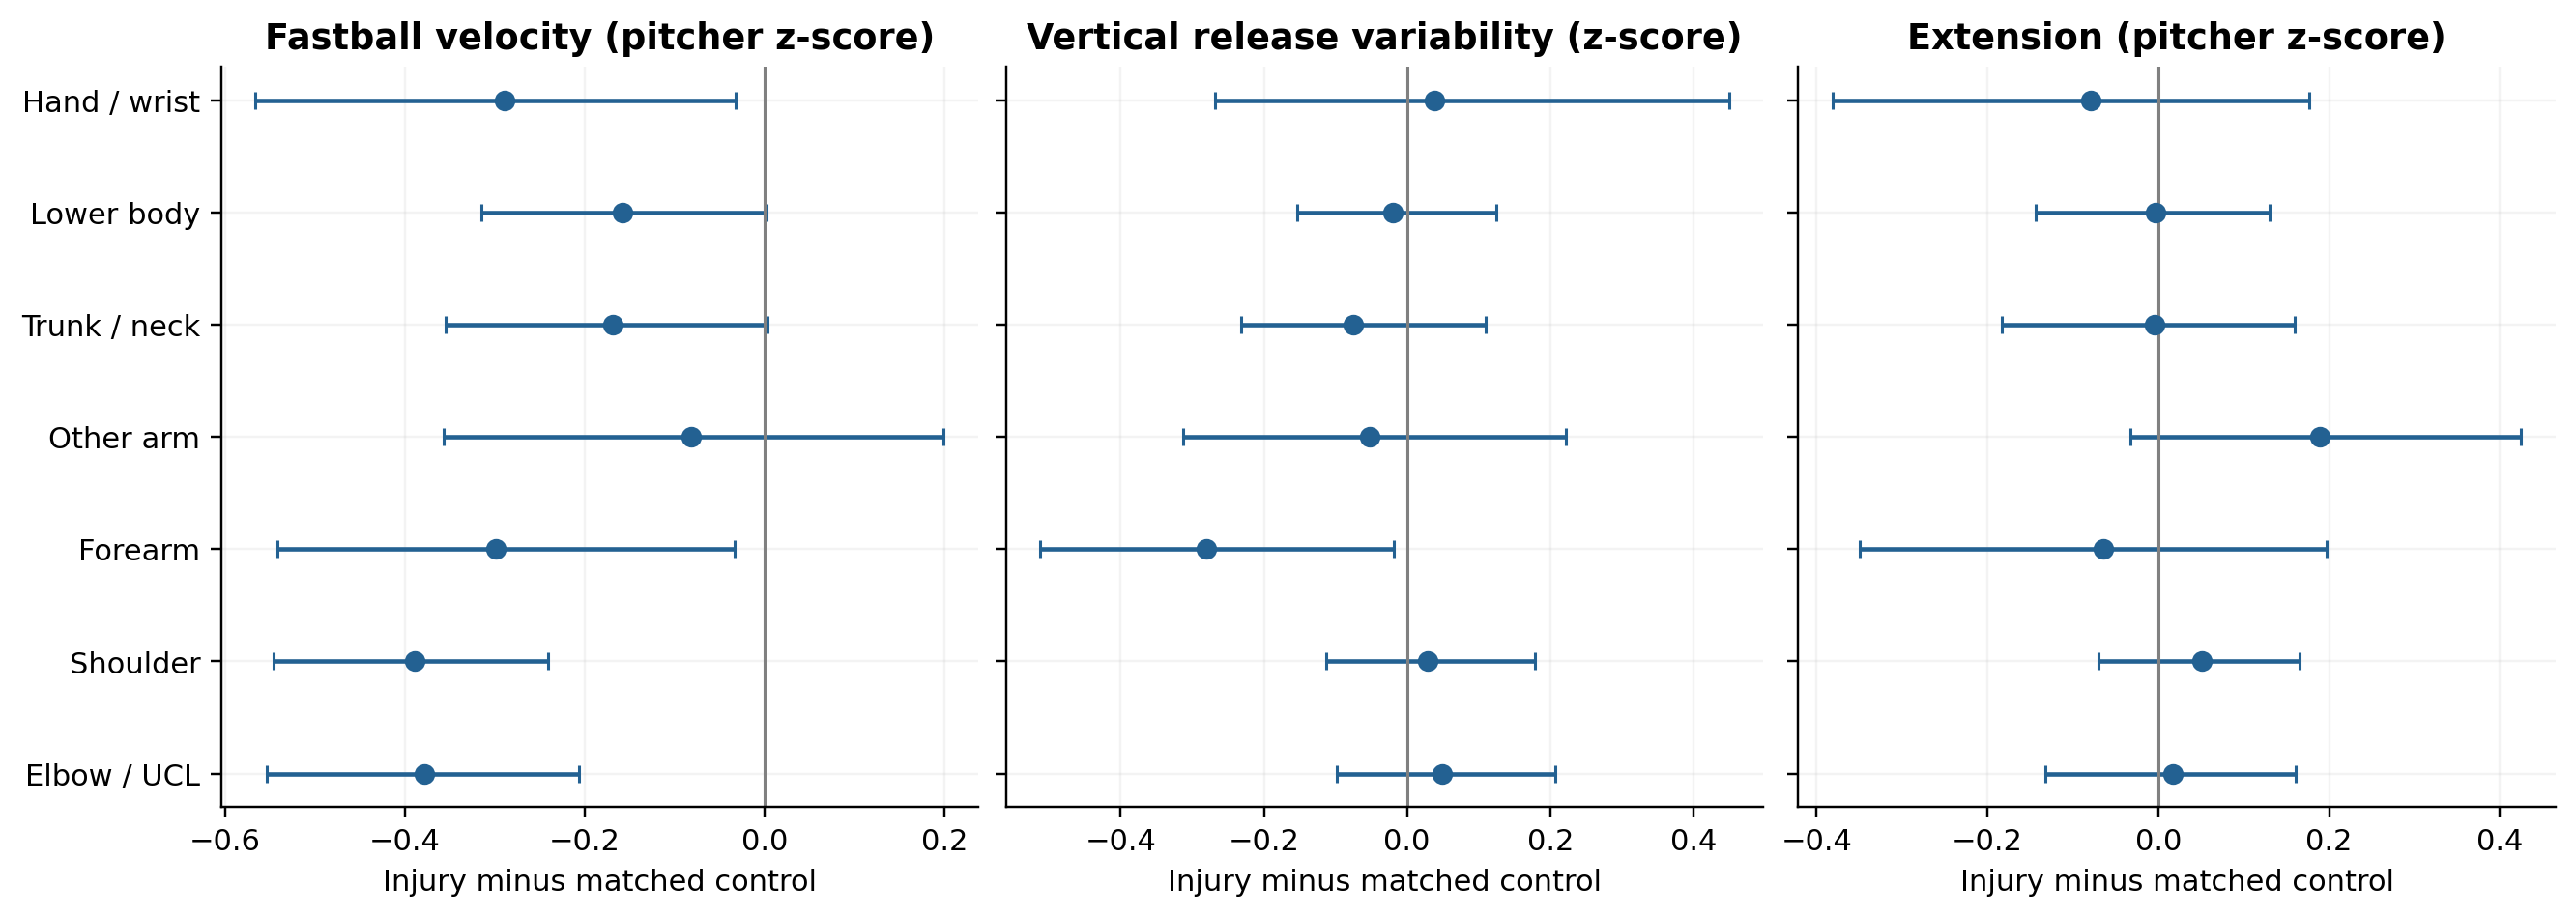

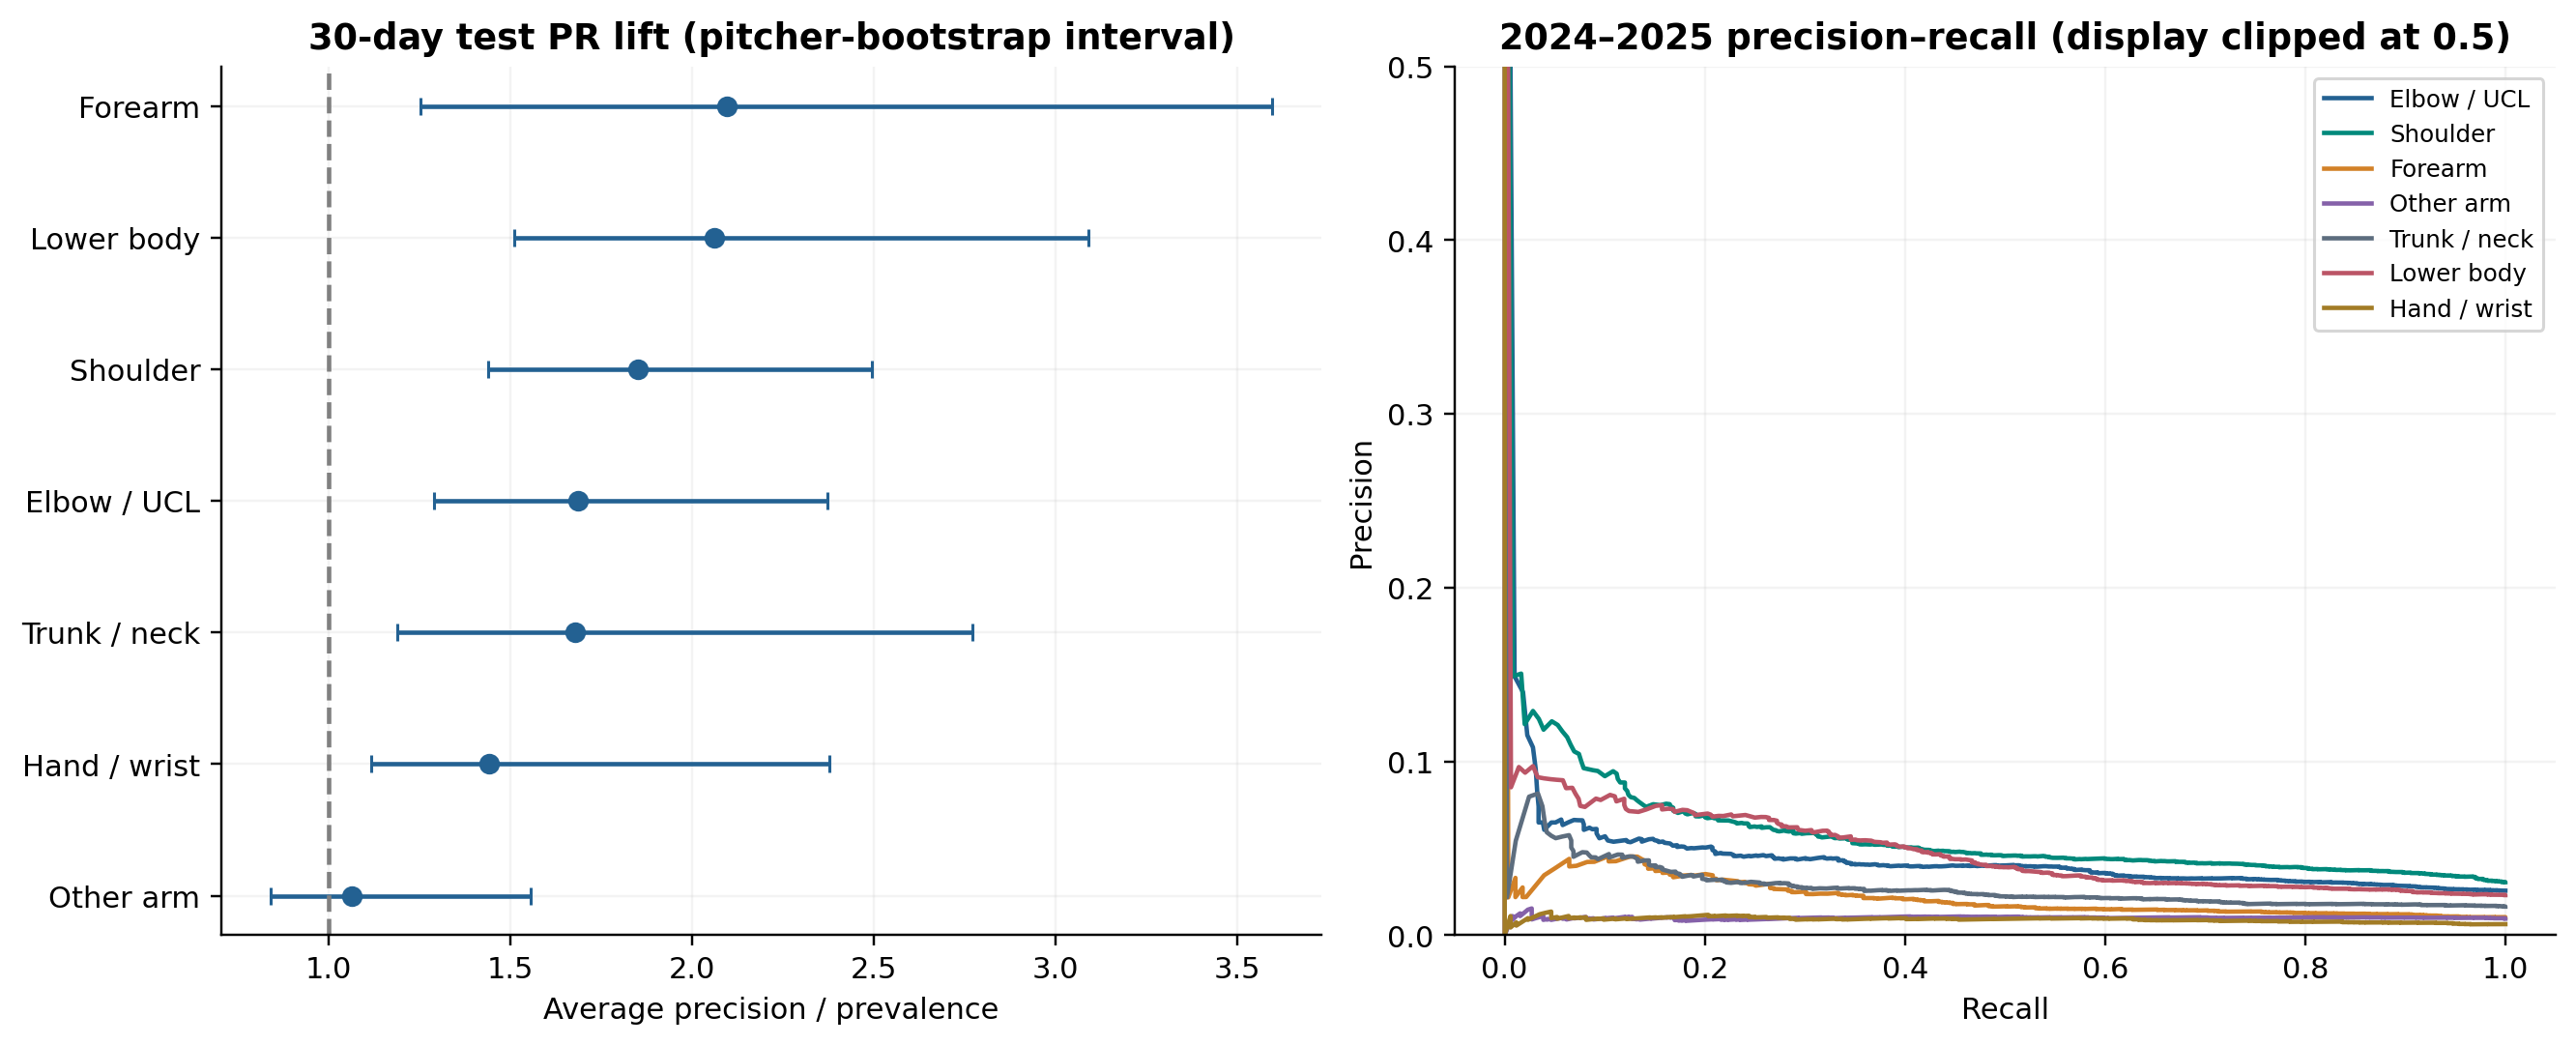

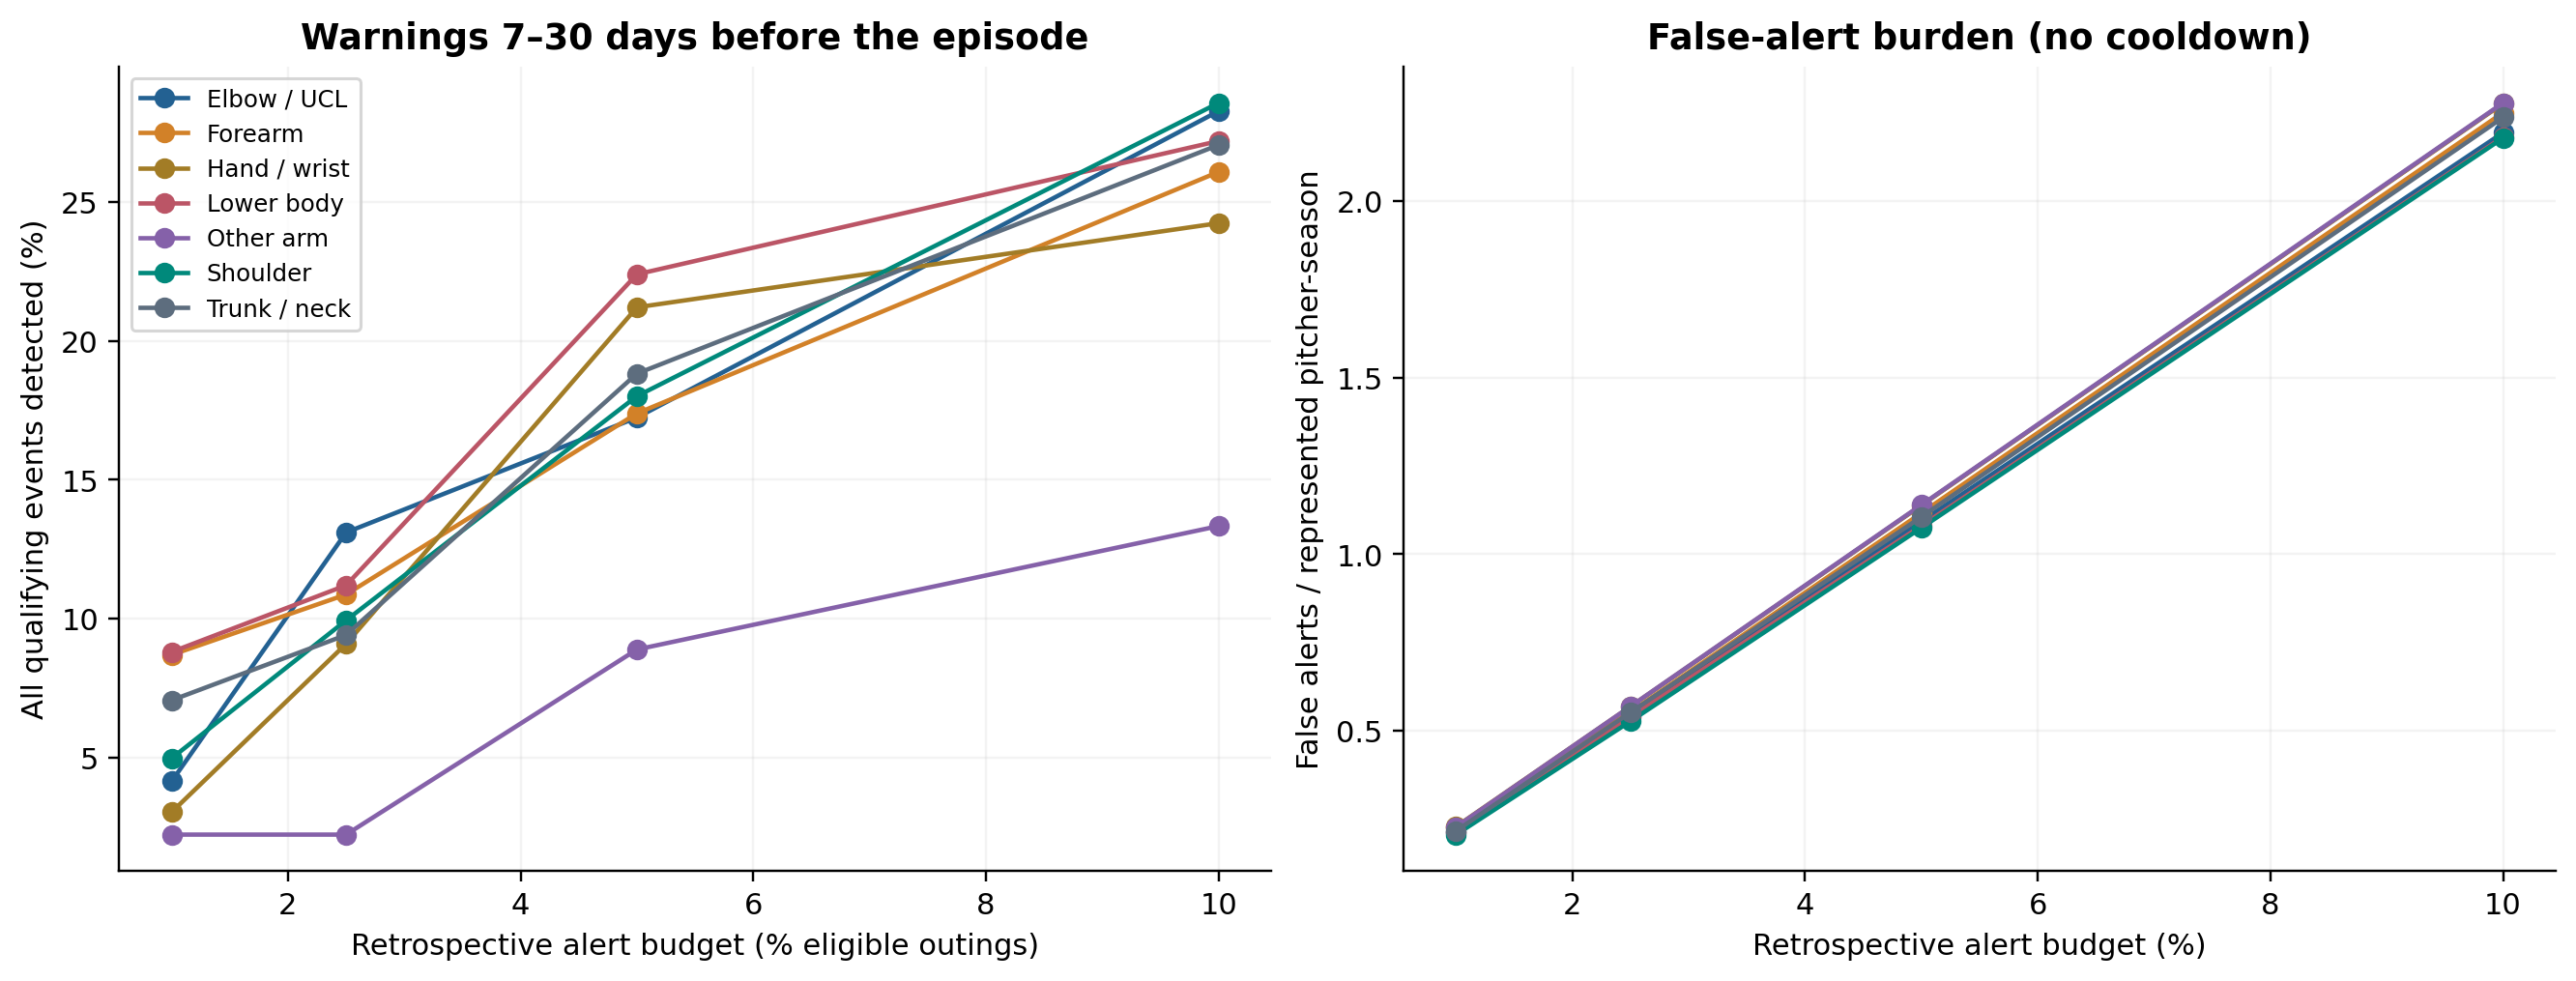

,check,passed
0,unique pitcher/game keys,True
1,strictly prior rolling/workload dates,True
2,positive events confined to one retained parti...,True
3,current/future outcome fields excluded from X,True
4,database size and mtime unchanged,True
5,all negative labels have observed horizon foll...,True


Full computed narrative: /Users/garrettgall/Desktop/MLB pitch stats/mlb_ucl_project/reports/injury_type_analysis/SUMMARY.md
Tables: /Users/garrettgall/Desktop/MLB pitch stats/mlb_ucl_project/reports/injury_type_analysis/tables
PNG/PDF figures: /Users/garrettgall/Desktop/MLB pitch stats/mlb_ucl_project/reports/injury_type_analysis/figures


**Computed conclusion.** The workflow analyzed 3,552 target-eligible documented episodes with 62 shared historical predictors. The computed summary above reports the observed effects, uncertain category differences, warning burden and recurrence patterns. The next step is targeted date/anatomy adjudication and a prespecified replication; these results do not yet justify a final injury-specific warning system.

In [3]:
from IPython.display import Image
for name in ['02_matched_effects','03_predictability','06_warning_budgets']:
    display(Image(filename=str(OUT/'figures'/f'{name}.png'),width=1000))
display(read_table('analysis_validation_checks'))
print('Full computed narrative:', OUT/'SUMMARY.md')
print('Tables:', OUT/'tables')
print('PNG/PDF figures:', OUT/'figures')
conclusion(f"The workflow analyzed {events.target_eligible.sum():,} target-eligible documented episodes with {spec.selected_for_prediction.sum()} shared historical predictors. The computed summary above reports the observed effects, uncertain category differences, warning burden and recurrence patterns. The next step is targeted date/anatomy adjudication and a prespecified replication; these results do not yet justify a final injury-specific warning system.")